Observations: [1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0]

Current Day | Smoothed Day | Rainy | Not Rainy | Error
------------------------------------------------------------
          4 |            1 | 0.8964 | 0.1036 | 0.00e+00
          5 |            2 | 0.9357 | 0.0643 | 1.39e-17
          6 |            3 | 0.9422 | 0.0578 | 2.22e-16
          7 |            4 | 0.9433 | 0.0567 | 4.58e-16
          8 |            5 | 0.9435 | 0.0565 | 2.73e-15
          9 |            6 | 0.9403 | 0.0597 | 1.65e-14
         10 |            7 | 0.9259 | 0.0741 | 1.00e-13
         11 |            8 | 0.8295 | 0.1705 | 6.09e-13
         12 |            9 | 0.2577 | 0.7423 | 3.70e-12
         13 |           10 | 0.6049 | 0.3951 | 1.39e-11
         14 |           11 | 0.1966 | 0.8034 | 4.27e-11
         15 |           12 | 0.5536 | 0.4464 | 1.89e-10
         16 |           13 | 0.0969 | 0.9031 | 5.66e-10
         17 |           14 | 0.1193 | 0.8807 | 2.54e-09
         18 |           

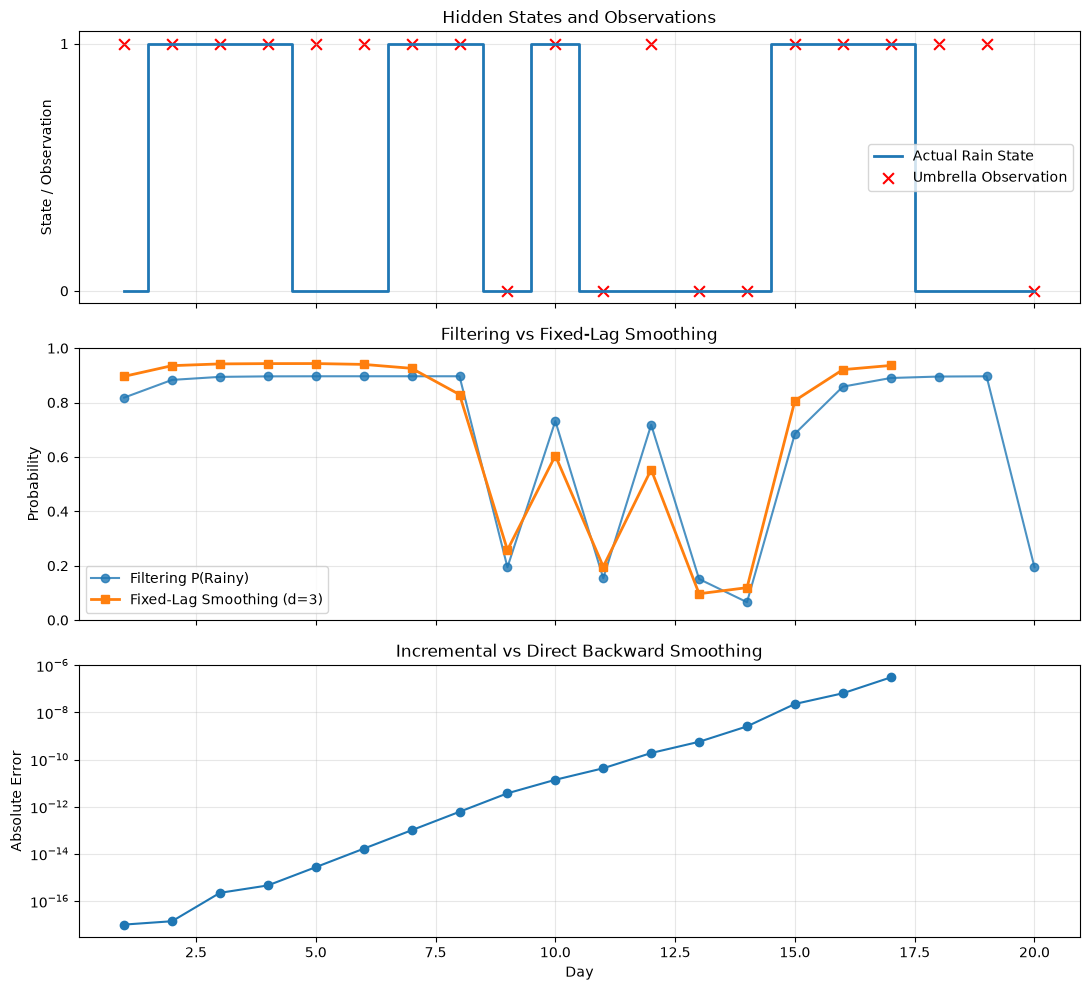

In [ ]:
#ORIGINAL CODE

import numpy as np
import matplotlib.pyplot as plt
#Define HMM parameters

T = np.array([[0.7, 0.3],
              [0.3, 0.7]])
O = {
    1: np.diag([0.9, 0.2]),  # Umbrella = Yes
    0: np.diag([0.1, 0.8])   # Umbrella = No
}

N, d = 20, 3
rng = np.random.default_rng(12)

#Generate random hidden states and observations

hidden = []
observations = []
state = rng.choice(2, p=[0.5, 0.5])

for i in range(N):
    state = rng.choice(2, p=T[state])
    umbrella = int(rng.random() < [0.9, 0.2][state])
    hidden.append(state)
    observations.append(umbrella)

print("Observations:", observations)

#Filtering

def filter_step(f, e):
    f = O[e] @ T.T @ f
    return f / f.sum()

f = np.array([0.5, 0.5])
filtered = []

for obs in observations:
    f = filter_step(f, obs)
    filtered.append(f.copy())

filtered = np.array(filtered)

# Direct backward recursion for verification
def backward(k, t):
    b = np.ones(2)
    for i in range(t - 1, k - 1, -1):
        b = T @ O[observations[i]] @ b
    return b

#Incremental fixed-lag smoothing
f = filtered[0].copy()
k = 1
t = k + d

B = np.eye(2)
for i in range(k, t):
    B = B @ T @ O[observations[i]]

smoothed = np.full((N, 2), np.nan)
errors = []

print("\nCurrent Day | Smoothed Day | Rainy | Not Rainy | Error")
print("-" * 60)

while True:
    # Compute smoothed distribution
    b = B @ np.ones(2)
    smooth = f * b
    smooth = smooth / smooth.sum()

    smoothed[k - 1] = smooth

    # Verify using direct backward recursion
    b_direct = backward(k, t)
    direct = f * b_direct
    direct = direct / direct.sum()

    error = np.max(np.abs(smooth - direct))
    errors.append(error)

    print(f"{t:11} | {k:12} | {smooth[0]:.4f} "
          f"| {smooth[1]:.4f} | {error:.2e}")

    if t == N:
        break

    # B_new = O_old^(-1) T^(-1) B_old T O_new
    B = np.linalg.solve(
        O[observations[k]],
        np.linalg.solve(T, B)
    ) @ T @ O[observations[t]]

    # Advance the forward message
    f = filter_step(f, observations[k])
    k += 1
    t += 1

print("\nMaximum verification error:", max(errors))

#Plot filtering and smoothing results
days = np.arange(1, N + 1)
valid = ~np.isnan(smoothed[:, 0])

fig, ax = plt.subplots(3, 1, figsize=(11, 10),
                       sharex=True)

# Actual hidden states and observations
actual_rain = 1 - np.array(hidden)

ax[0].step(days, actual_rain, where="mid",
           label="Actual Rain State", linewidth=2)
ax[0].scatter(days, observations, marker="x",
              color="red", s=60, label="Umbrella Observation")
ax[0].set_ylabel("State / Observation")
ax[0].set_title("Hidden States and Observations")
ax[0].set_yticks([0, 1])
ax[0].legend()
ax[0].grid(True, alpha=0.3)

#Filtering and fixed-lag smoothing
ax[1].plot(days, filtered[:, 0], "o-",
           label="Filtering P(Rainy)", alpha=0.8)

ax[1].plot(days[valid], smoothed[valid, 0], "s-",
           label=f"Fixed-Lag Smoothing (d={d})",
           linewidth=2)

ax[1].set_ylabel("Probability")
ax[1].set_title("Filtering vs Fixed-Lag Smoothing")
ax[1].set_ylim(0, 1)
ax[1].legend()
ax[1].grid(True, alpha=0.3)

#Verification error
ax[2].semilogy(days[valid],
               np.maximum(errors, 1e-17), "o-")
ax[2].set_xlabel("Day")
ax[2].set_ylabel("Absolute Error")
ax[2].set_title("Incremental vs Direct Backward Smoothing")
ax[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("HMM_Fixed_Lag_Smoothing.png", dpi=300)
plt.show()


Observations: [1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0]

Current Day | Smoothed Day | Rainy | Not Rainy | Error
------------------------------------------------------------
          4 |            1 | 0.8964 | 0.1036 | 0.00e+00
          5 |            2 | 0.9357 | 0.0643 | 1.39e-17
          6 |            3 | 0.9422 | 0.0578 | 2.22e-16
          7 |            4 | 0.9433 | 0.0567 | 4.58e-16
          8 |            5 | 0.9435 | 0.0565 | 2.73e-15
          9 |            6 | 0.9403 | 0.0597 | 1.65e-14
         10 |            7 | 0.9259 | 0.0741 | 1.00e-13
         11 |            8 | 0.8295 | 0.1705 | 6.09e-13
         12 |            9 | 0.2577 | 0.7423 | 3.70e-12
         13 |           10 | 0.6049 | 0.3951 | 1.39e-11
         14 |           11 | 0.1966 | 0.8034 | 4.27e-11
         15 |           12 | 0.5536 | 0.4464 | 1.89e-10
         16 |           13 | 0.0969 | 0.9031 | 5.66e-10
         17 |           14 | 0.1193 | 0.8807 | 2.54e-09
         18 |           

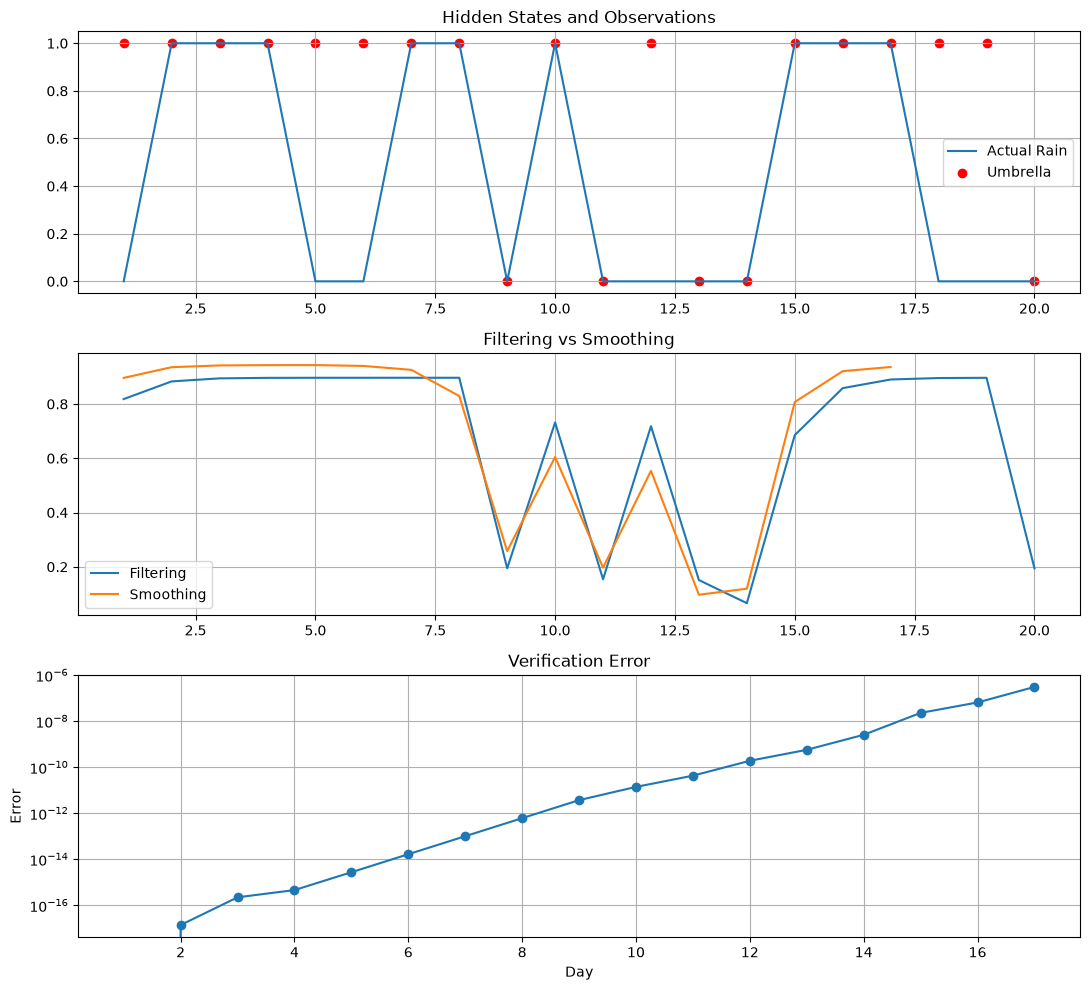

In [ ]:
#STUDIED
import numpy as np
import matplotlib.pyplot as plt

T = np.array([[0.7, 0.3], [0.3, 0.7]])
O = {1: np.diag([0.9, 0.2]),
     0: np.diag([0.1, 0.8])}
N, d = 20, 3
rng = np.random.default_rng(12)

# Generate data
hidden, observations = [], []
state = rng.choice(2, p=[0.5, 0.5])

for i in range(N):
    state = rng.choice(2, p=T[state])
    hidden.append(state)
    observations.append(int(rng.random() < [0.9, 0.2][state]))

print("Observations:", observations)

# Filtering
def filter_step(f, e):
    f = O[e] @ T.T @ f
    return f / f.sum()

f = np.array([0.5, 0.5])
filtered = []
                                          
for obs in observations:
    f = filter_step(f, obs)
    filtered.append(f.copy())

filtered = np.array(filtered)

# Backward recursion
def backward(k, t):
    b = np.ones(2)
    for i in range(t-1, k-1, -1):
        b = T @ O[observations[i]] @ b
    return b

# Fixed-lag smoothing
f, k, t = filtered[0].copy(), 1, 1+d
B = np.eye(2)
for i in range(k, t):
    B = B @ T @ O[observations[i]]

smoothed = np.full((N, 2), np.nan)
errors = []

print("\nCurrent Day | Smoothed Day | Rainy | Not Rainy | Error")
print("-" * 60)

while True:
    b = B @ np.ones(2)
    smooth = f * b
    smooth /= smooth.sum()
    smoothed[k-1] = smooth

    direct = f * backward(k, t)
    direct /= direct.sum()
    error = np.max(np.abs(smooth-direct))
    errors.append(error)
    print(f"{t:11} | {k:12} | {smooth[0]:.4f} "
          f"| {smooth[1]:.4f} | {error:.2e}")

    
    if t == N:
        break

    B = np.linalg.solve(O[observations[k]],
        np.linalg.solve(T, B)) @ T @ O[observations[t]]

    f = filter_step(f, observations[k])
    k, t = k+1, t+1

print("\nMaximum verification error:", max(errors))


days = np.arange(1, N+1)
valid = ~np.isnan(smoothed[:, 0])

fig, ax = plt.subplots(3, 1, figsize=(11, 10))

# Graph 1: Hidden states and observations
ax[0].plot(days, 1-np.array(hidden), label="Actual Rain")
ax[0].scatter(days, observations, label="Umbrella", color="red")
ax[0].set_title("Hidden States and Observations")
ax[0].legend()
ax[0].grid()

# Graph 2: Filtering and Smoothing
ax[1].plot(days, filtered[:, 0], label="Filtering")
ax[1].plot(days[valid], smoothed[valid, 0], label="Smoothing")
ax[1].set_title("Filtering vs Smoothing")
ax[1].legend()
ax[1].grid()

# Graph 3: Verification Error
ax[2].semilogy(days[valid], errors, "o-")
ax[2].set_title("Verification Error")
ax[2].set_xlabel("Day")
ax[2].set_ylabel("Error")
ax[2].grid()

plt.tight_layout()
plt.savefig("HMM.png")
plt.show()


Observations: [1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1]
          3 |            1 | 0.6839 | 0.3161 | 3.05e-07
          4 |            2 | 0.1098 | 0.8902 | 3.05e-07
          5 |            3 | 0.1213 | 0.8787 | 3.05e-07
          6 |            4 | 0.7523 | 0.2477 | 3.05e-07
          7 |            5 | 0.7808 | 0.2192 | 3.05e-07
          8 |            6 | 0.2384 | 0.7616 | 3.05e-07
          9 |            7 | 0.6114 | 0.3886 | 3.05e-07
         10 |            8 | 0.2543 | 0.7457 | 3.05e-07
         11 |            9 | 0.7793 | 0.2207 | 3.05e-07
         12 |           10 | 0.7895 | 0.2105 | 3.05e-07
Maximum verification error: 3.685024507760204e-12


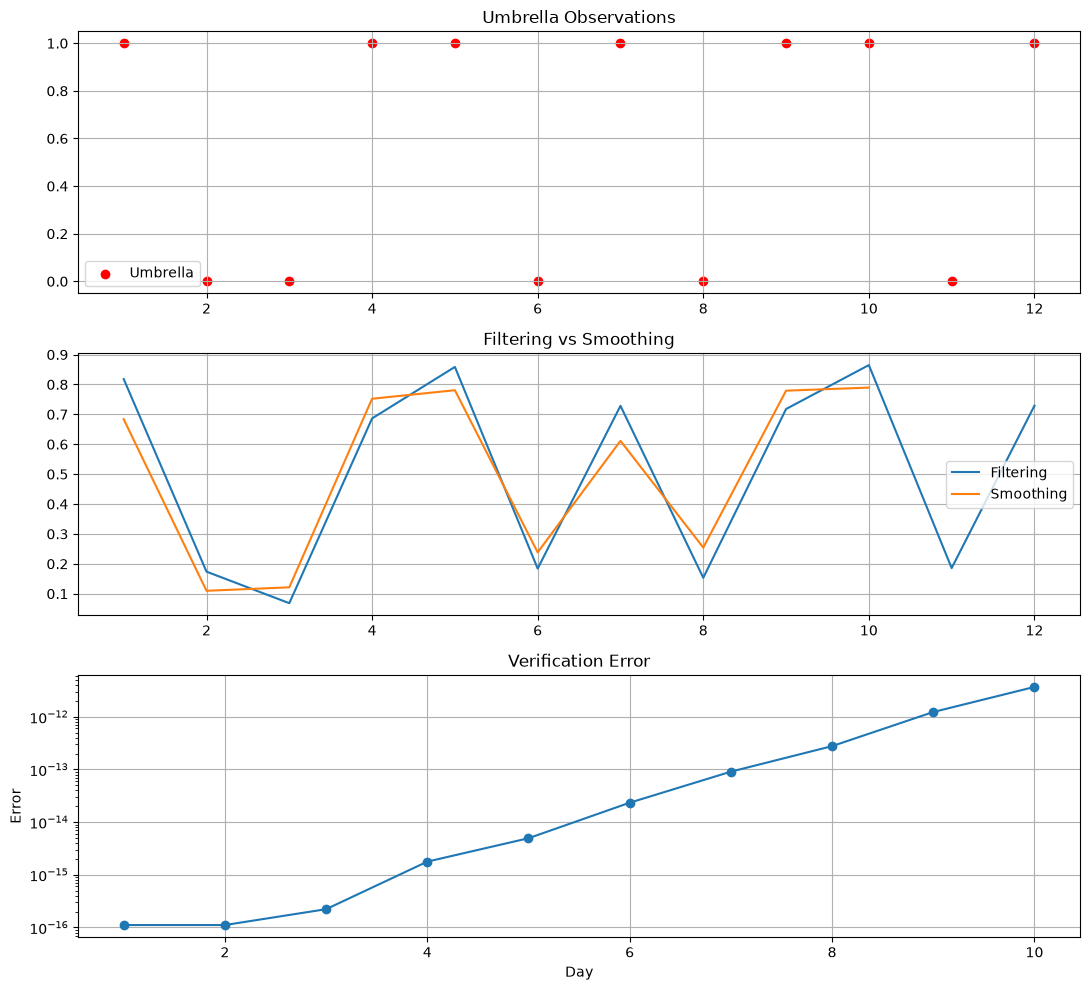

In [ ]:
#ANOTHER EXAMPLE
import numpy as np
import matplotlib.pyplot as plt

T = np.array([[0.7, 0.3], [0.3, 0.7]])
O = {1: np.diag([0.9, 0.2]), 0: np.diag([0.1, 0.8])}

observations = [1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1]
N, d = len(observations), 2

print("Observations:", observations)

# Filtering
def filter_step(f, e):
    f = O[e] @ T.T @ f
    return f / f.sum()

f = np.array([0.5, 0.5])
filtered = []

for obs in observations:
    f = filter_step(f, obs)
    filtered.append(f.copy())

filtered = np.array(filtered)

# Backward recursion
def backward(k, t):
    b = np.ones(2)
    for i in range(t-1, k-1, -1):
        b = T @ O[observations[i]] @ b
    return b

# Fixed-lag smoothing
f, k, t = filtered[0].copy(), 1, 1+d
B = np.eye(2)

for i in range(k, t):
    B = B @ T @ O[observations[i]]

smoothed = np.full((N, 2), np.nan)
errors = []

while True:
    b = B @ np.ones(2)
    smooth = f * b
    smooth /= smooth.sum()
    smoothed[k-1] = smooth

    direct = f * backward(k, t)
    direct /= direct.sum()
    errors.append(np.max(np.abs(smooth-direct)))
    
    print(f"{t:11} | {k:12} | {smooth[0]:.4f} "
          f"| {smooth[1]:.4f} | {error:.2e}")


    if t == N:
        break

    B = np.linalg.solve(O[observations[k]],
        np.linalg.solve(T, B)) @ T @ O[observations[t]]

    f = filter_step(f, observations[k])
    k, t = k+1, t+1

print("Maximum verification error:", max(errors))

# Plot results
days = np.arange(1, N+1)
valid = ~np.isnan(smoothed[:, 0])

fig, ax = plt.subplots(3, 1, figsize=(11, 10))

# Graph 1: Observations
ax[0].scatter(days, observations, color="red", label="Umbrella")
ax[0].set_title("Umbrella Observations")
ax[0].legend()
ax[0].grid()

# Graph 2: Filtering and Smoothing
ax[1].plot(days, filtered[:, 0], label="Filtering")
ax[1].plot(days[valid], smoothed[valid, 0], label="Smoothing")
ax[1].set_title("Filtering vs Smoothing")
ax[1].legend()
ax[1].grid()

# Graph 3: Verification Error
ax[2].semilogy(days[valid], errors, "o-")
ax[2].set_title("Verification Error")
ax[2].set_xlabel("Day")
ax[2].set_ylabel("Error")
ax[2].grid()

plt.tight_layout()
plt.savefig("HMM.png")
plt.show()
